# image→audio schemes for generational loss: which decays most interestingly?

Loop: **image → audio → speaker → room → mic → audio → image → blend with the camera → repeat**.

Offline experiment with no camera/speaker: sends one still image through dozens of passes of a simulated room and compare how each encoding scheme affects it.

In [50]:
%load_ext autoreload
%autoreload 2

import cv2
from IPython.display import Audio, display
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import correlate, fftconvolve, sosfreqz, stft

# Our AV loop library
from loopdsp import LoopConfig, codecs, channel, blend
from loopdsp.loop import make_state, step, run_generations

plt.rcParams.update({"figure.dpi": 110, "image.cmap": "gray"})

# Calcualte how similar two images (or 1D signals) are
def corr(a, b):
    # normalized correlation at zero lag: 1 = same structure, 0 = unrelated
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-12))

# Plot images in a row
def show_row(*imgs, titles=None, size=2.6, **kw):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size))
    for ax, im, t in zip(np.atleast_1d(axes), imgs, titles or [""] * len(imgs)):
        ax.imshow(im, **kw); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. The frame budget
There's a physical cap on bandwidth: ~20,000 Hz since the audio channel is capped by human hearing (20Hz - 20,000Hz).
Can't make bandwidth wider -> only way to increase video frame rate is to spend fewer samples on each frame:

$$\text{samples per frame} = \frac{f_s}{\text{fps}} \qquad\Rightarrow\qquad 48\,000 / 10 = 4800$$

A short sync pulse goes at the start of each frame (see section 4), and the rest carries the image.

In [51]:
# Set up loop config and print parameters
cfg = LoopConfig()
H, W = cfg.shape
print(f"fs = {cfg.fs} Hz, {cfg.fps} fps -> {cfg.frame_len} samples/frame")
print(f"sync pulse {cfg.frame_len - cfg.payload_len} samples, payload {cfg.payload_len} samples")
print(f"image {W}x{H} = {W*H} px -> {cfg.payload_len / (W*H):.2f} samples per pixel (raster)")
for name, (w, h) in {"360x360": (360, 360), "SD 720x480": (720, 480)}.items():
    print(f"  for comparison, {name} at 1 sample/px: {w*h/cfg.fs:.1f} s per frame")

fs = 48000 Hz, 10.0 fps -> 4800 samples/frame
sync pulse 480 samples, payload 4320 samples
image 64x48 = 3072 px -> 1.41 samples per pixel (raster)
  for comparison, 360x360 at 1 sample/px: 2.7 s per frame
  for comparison, SD 720x480 at 1 sample/px: 7.2 s per frame


## 2. Test image

Load in test image or synthetic pattern that makes artifacts easy to read

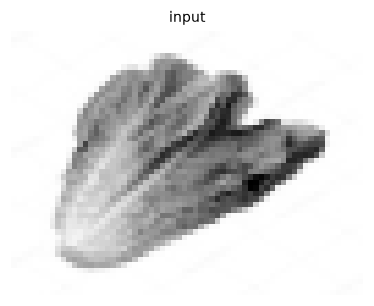

In [52]:
img = codecs.test_pattern(cfg.shape)
img = cv2.resize(cv2.imread("lettuce.jpg", cv2.IMREAD_GRAYSCALE), (W, H), interpolation=cv2.INTER_AREA).astype(np.float32) / 255
show_row(img, titles=["input"], size=3.5, cmap=None)

## 3. Four encoding schemes

| scheme | idea | information carried by |
|---|---|---|
| **raster** | scan rows like a CRT beam | sample **amplitude** |
| **fm** | one oscillator whose pitch follows brightness | **frequency** |
| **spectrogram** | image *is* the spectrogram | **energy at each pitch over time** |
| **dct** | lowest-N 2D DCT coefficients, each held as a level | **transform coefficients** |

### 3a. Direct rasterization

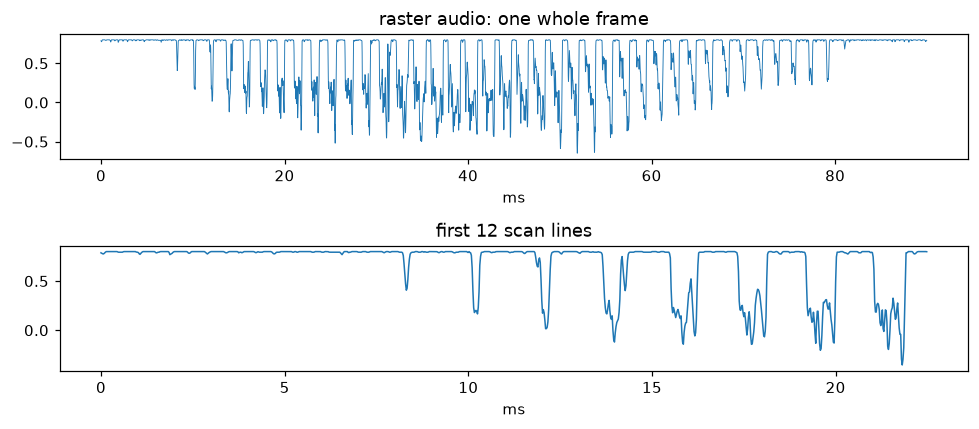

In [71]:
# Flatten img row by row, stretch to the payload length
samples = codecs.raster_encode(img, cfg.payload_len)

# time axis: which moment each sample is played at, in ms
t_ms = np.arange(cfg.payload_len) / cfg.fs * 1000
fig, ax = plt.subplots(2, 1, figsize=(9, 4))

# whole frame: 48 scan lines back to back (90 ms)
ax[0].plot(t_ms, samples, lw=0.6); ax[0].set_title("raster audio: one whole frame"); ax[0].set_xlabel("ms")

# first 12 scan lines (~22 ms)
seg = slice(0, 12 * cfg.payload_len // H)
ax[1].plot(t_ms[seg], samples[seg], lw=1); ax[1].set_title("first 12 scan lines"); ax[1].set_xlabel("ms")
plt.tight_layout(); plt.show()

# Play as audio
display(Audio(np.tile(samples, 10), rate=cfg.fs))   # 10 frames = 1 second

Fundamental frequency:
Each row lasts `payload_len / H` samples, so a static image repeats at that rate

In [54]:
row_hz = cfg.fs / (cfg.payload_len / H)
print(f"row repetition rate ~ {row_hz:.0f} Hz (the raster 'buzz' fundamental)")

row repetition rate ~ 533 Hz (the raster 'buzz' fundamental)


### 3b. What each scheme sounds like and how well they survive perfect channel

The spectrogram codec loses the most even through a perfect channel, because the image only supplies magnitudes and the phase has to be estimated (Griffin-Lim).

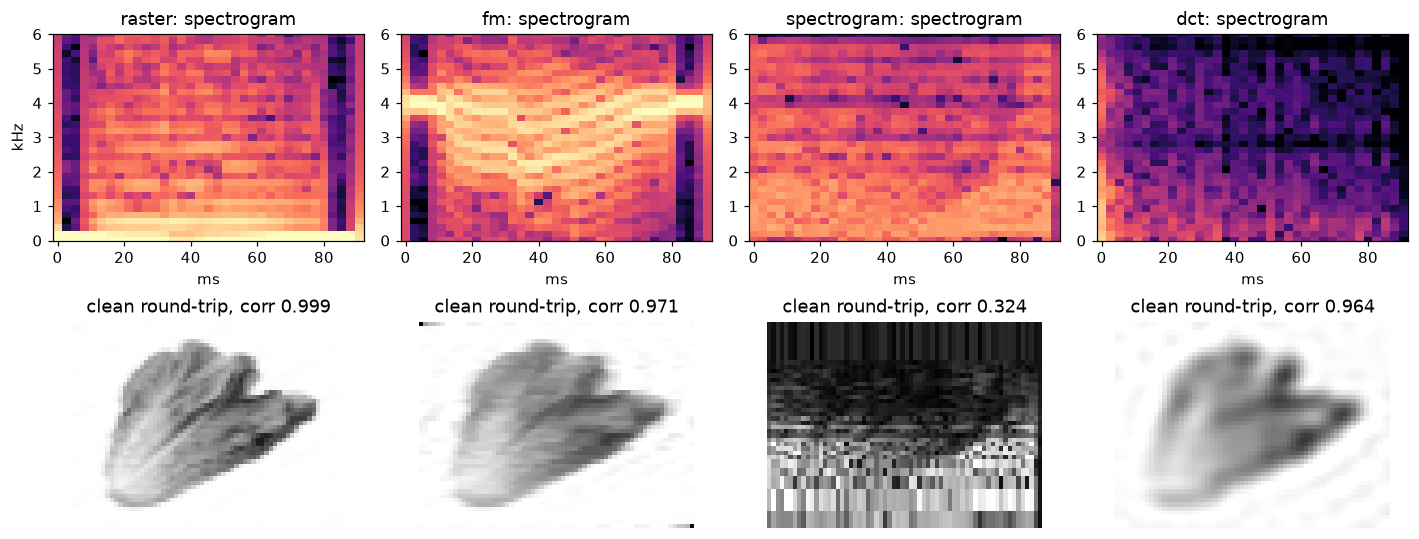

raster


fm


spectrogram


dct


In [55]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for k, (name, (enc, dec)) in enumerate(codecs.CODECS.items()):
    audio = enc(img, cfg.payload_len)
    back = dec(audio, cfg.shape)
    f, t, Z = stft(audio, fs=cfg.fs, nperseg=256)
    axes[0, k].pcolormesh(t * 1000, f / 1000, 20 * np.log10(np.abs(Z) + 1e-6),
                          vmin=-80, vmax=-10, cmap="magma", shading="auto")
    axes[0, k].set_ylim(0, 6); axes[0, k].set_title(f"{name}: spectrogram"); axes[0, k].set_xlabel("ms")
    axes[1, k].imshow(back, vmin=0, vmax=1); axes[1, k].axis("off")
    axes[1, k].set_title(f"clean round-trip, corr {corr(img, back):.3f}")
axes[0, 0].set_ylabel("kHz")
plt.tight_layout(); plt.show()

for name, (enc, _) in codecs.CODECS.items():
    print(name); display(Audio(np.tile(enc(img, cfg.payload_len), 10), rate=cfg.fs))

## 4. Syncing: finding where each frame starts

After the room the audio is delayed by an unknown amount. Each frame starts with a known pulse,
and the receiver **cross-correlates** with it (a matched filter). The peak marks the frame start.

The pulse is a chirp (downward sweep, sounds like a kick drum) rather than a pure tone.
A pure tone's autocorrelation has a peak every cycle, and the neighbors are nearly as tall as the true peak -> makes it easy for receiver to lock a cycle early or late once the speaker's filtering shifts the tone's phase.

A sweep's side peaks are much lower -> true alignment stands out.

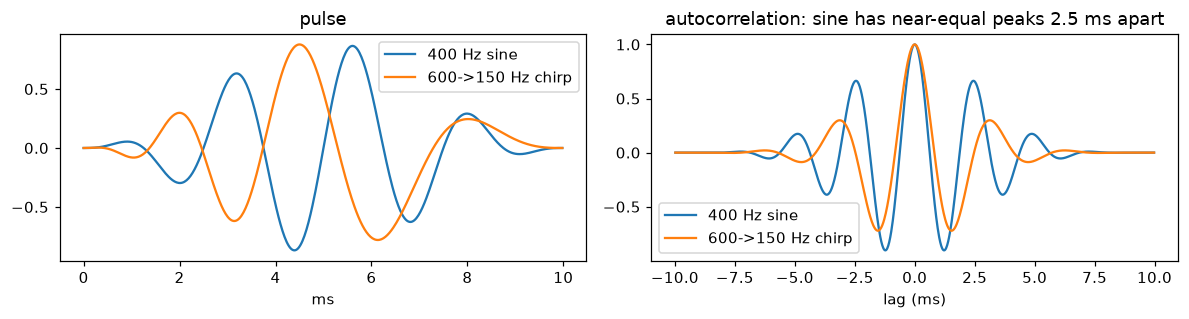

In [72]:
# Real sync pulse (600 -> 150 Hz chirp), and a plain sine of the same length for comparison
chirp_ = channel.sync_pulse(cfg.fs, cfg.sync_ms)
n = len(chirp_)                                           # 480 samples = 10 ms
t = np.arange(n) / cfg.fs                                 # time of each sample, in seconds
sine = 0.9 * np.hanning(n) * np.sin(2 * np.pi * 400 * t)  # same fade in/out as the chirp

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for sig, label in [(sine, "400 Hz sine"), (chirp_, "600->150 Hz chirp")]:
    # Autocorrelation: how well the pulse matches a shifted copy of itself (peak scaled to 1)
    ac = correlate(sig, sig, mode="full"); ac /= ac.max()

    # Shift for each autocorrelation value, in ms (0 = perfectly aligned)
    lags = (np.arange(len(ac)) - len(sig) + 1) / cfg.fs * 1000

    ax[0].plot(t * 1000, sig, label=label); ax[1].plot(lags, ac, label=label)

# Left: the pulses. Right: sine has near-equal side peaks; chirp has one clear peak
ax[0].set_title("pulse"); ax[0].set_xlabel("ms"); ax[0].legend()
ax[1].set_title("autocorrelation: sine has near-equal peaks 2.5 ms apart"); ax[1].set_xlabel("lag (ms)"); ax[1].legend()
plt.tight_layout(); plt.show()

# Play the sync rhythm alone: pulse + silent payload, 10 frames = 1 second
display(Audio(np.tile(np.concatenate([chirp_, np.zeros(cfg.payload_len)]), 10), rate=cfg.fs))

## 5. Simulated room

`SimulatedRoom` applies, in order: speaker/mic **band-limiting**, **room modes** (resonant peaks),
**reverb** (convolution with an impulse response), **delay**, **clock drift** and **noise**.
The reverb tail of one frame spills into the next (overlap-add).

### 5a. Frequency response of the filters

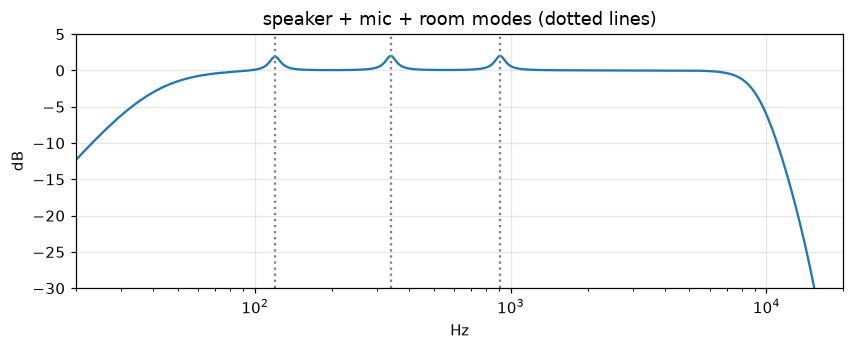

In [ ]:
# Room's filters: speaker bass cut, mic/speaker treble cut, and room-mode peaks
# (filters only; reverb, delay, drift and noise aren't shown here)
room = channel.SimulatedRoom(cfg.fs)

# Gain of the filters at 8192 frequencies from 0 Hz to 24 kHz
f, h = sosfreqz(room.sos, worN=8192, fs=cfg.fs)

plt.figure(figsize=(9, 3))
# Log frequency axis (skip 0 Hz, which a log scale can't show); gain in dB
plt.semilogx(f[1:], 20 * np.log10(np.abs(h[1:]) + 1e-9))   # +1e-9 avoids log(0)

# Mark the room-mode frequencies
for m in (120, 340, 910): plt.axvline(m, ls=":", c="gray")

# Range of human hearing; 0 dB = unchanged, negative = quieter
plt.xlim(20, 20000); plt.ylim(-30, 5); plt.grid(alpha=0.3)
plt.title("speaker + mic + room modes (dotted lines)"); plt.xlabel("Hz"); plt.ylabel("dB")
plt.show()

### 5b. Reverb is convolution

$y[n] = \sum_k h[k]\,x[n-k]$, where $h$ is the room's impulse response (what the mic records from a single click).

Shows that room's sound equals the original audio convolved with the room's impulse response (IR).
Below it's written out directly and checked against `fftconvolve`, which does the same thing via
$Y = X \cdot H$ in the frequency domain (much faster for long $h$).

direct sum == fftconvolve: True


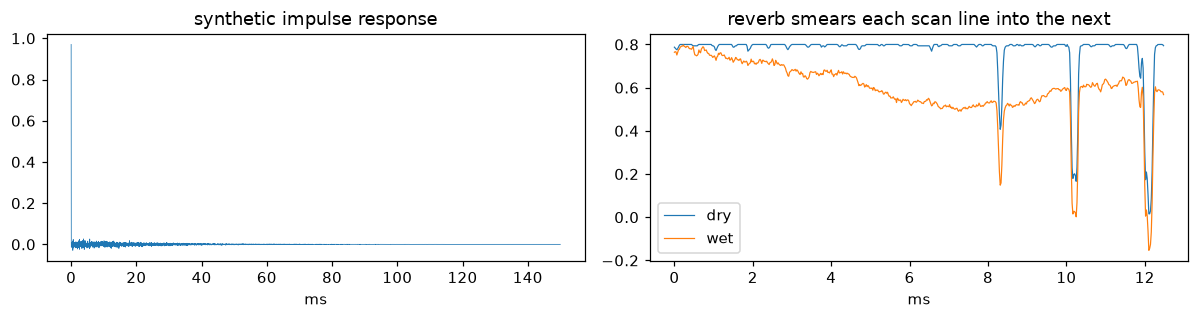

In [75]:
# Synthetic room impulse response: direct spike + decaying noise tail (rt60 = 0.15 s)
ir = channel.synthetic_ir(cfg.fs)                 # 7,200 samples = 150 ms
x = codecs.raster_encode(img, cfg.payload_len)[:2000]   # first ~22 scan lines (~42 ms)

# Convolution by hand: each output = past inputs weighted by the IR
h_short = ir[:300]                                # shortened so the Python loop is fast
y_direct = np.array([sum(h_short[k] * x[i - k] for k in range(len(h_short)) if 0 <= i - k < len(x))
                     for i in range(len(x))])

# Same thing via FFT (multiply spectra instead of summing in time)
y_fft = fftconvolve(x, h_short)[: len(x)]
print("direct sum == fftconvolve:", np.allclose(y_direct, y_fft, atol=1e-5))

fig, ax = plt.subplots(1, 2, figsize=(11, 3))

# Left: the impulse response over time
ax[0].plot(np.arange(len(ir)) / cfg.fs * 1000, ir, lw=0.5)
ax[0].set_title("synthetic impulse response"); ax[0].set_xlabel("ms")

# Right: first 600 samples (12.5 ms) before and after reverb
t_ms = np.arange(600) / cfg.fs * 1000
ax[1].plot(t_ms, x[:600], label="dry", lw=0.8)
ax[1].plot(t_ms, fftconvolve(x, ir)[:600], label="wet", lw=0.8)
ax[1].set_title("reverb smears each scan line into the next"); ax[1].set_xlabel("ms"); ax[1].legend()
plt.tight_layout(); plt.show()

# Optional: physically modeled room (pyroomacoustics) instead of the synthetic IR
# ir_room = channel.shoebox_ir(cfg.fs, room_dim=(6, 5, 3), rt60=0.5)   # 6x5x3 m room, 0.5 s reverb
# room = channel.SimulatedRoom(cfg.fs, ir=ir_room)

### 5c. Comparing stages (one pass, raster)

Compare different room effects on the loop by looking at one stage at a time. Each pass causes a little more to be lost.

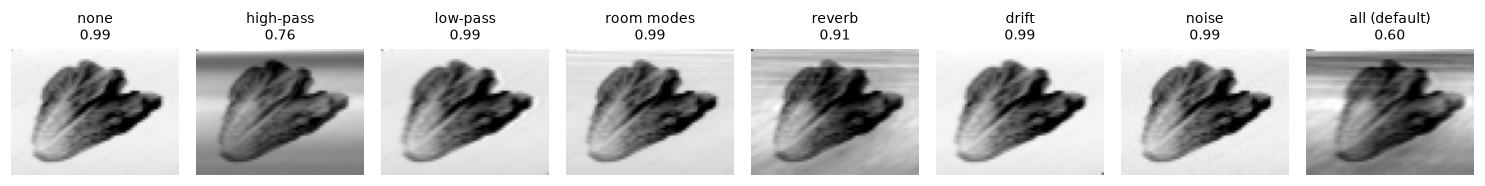

In [59]:
# Set default values for room params (overridden by stages)
off = {
    "highpass_hz": 1,
    "lowpass_hz": 23000,
    "room_modes_hz": (),
    "delay_ms": 0,
    "drift_ppm": 0,
    "noise_db": -150,
    "ir": np.array([1.0], np.float32),
}
# Map degradation stages to room params (None = default)
stages = {
    "none": {},
    "high-pass": {"highpass_hz": 40},
    "low-pass": {"lowpass_hz": 9000},
    "room modes": {"room_modes_hz": (120, 340, 910)},
    "reverb": {"ir": channel.synthetic_ir(cfg.fs)},
    "drift": {"drift_ppm": 50},
    "noise": {"noise_db": -40},
    "all (default)": None,
}
results = {}

# Test raster loop method on each degradation stage and store decoded images
# name: stage name, kw: room params
for name, kw in stages.items():
    rm = (
        channel.SimulatedRoom(cfg.fs)
        if kw is None
        else channel.SimulatedRoom(cfg.fs, **{**off, **kw})
    )
    cfg1 = LoopConfig(
        codec="raster", feedback=0.0
    )  # camera only: measures one pass, no loop
    st = make_state(cfg1, rm)
    for _ in range(4):
        _, dec, st = step(st, img)
    results[name] = dec

# Display results with correlation scores
show_row(
    *list(results.values()),
    titles=[f"{k}\n{corr(img, v):.2f}" for k, v in results.items()],
    size=1.7,
)

## 6. Generational loss: main experiment

Feed the image as the "camera" for 10 generations (blend "live" input with loop), then turn the camera off and let the loop run on its own.
`feedback` sets how much of each new frame comes from the loop versus the camera.

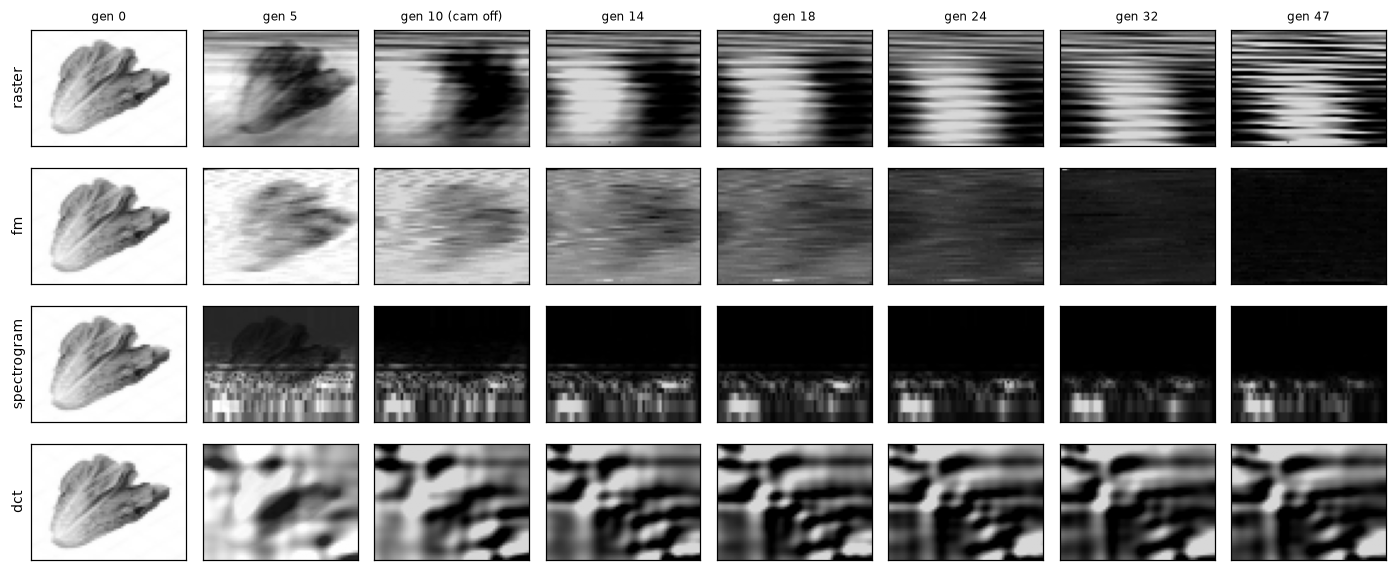

In [60]:
# number of generations to run, number of generations with camera on
N_GENS, CAMERA_GENS = 48, 10 
runs = {}

# Run the loop for each codec and store the frames and audio
for name in codecs.CODECS:
    frames, audio = run_generations(LoopConfig(codec=name), img, N_GENS, camera_gens=CAMERA_GENS)
    runs[name] = (frames, audio)

# Display the frames at selected generations for each codec
picks = [0, 5, 10, 14, 18, 24, 32, 47]
fig, axes = plt.subplots(len(runs), len(picks), figsize=(1.6 * len(picks), 1.35 * len(runs)))
for r, (name, (frames, _)) in enumerate(runs.items()):
    for c, g in enumerate(picks):
        axes[r, c].imshow(frames[g], vmin=0, vmax=1); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0: axes[r, c].set_title(f"gen {g}" + (" (cam off)" if g == CAMERA_GENS else ""), fontsize=8)
    axes[r, 0].set_ylabel(name, fontsize=9)
plt.tight_layout(); plt.show()

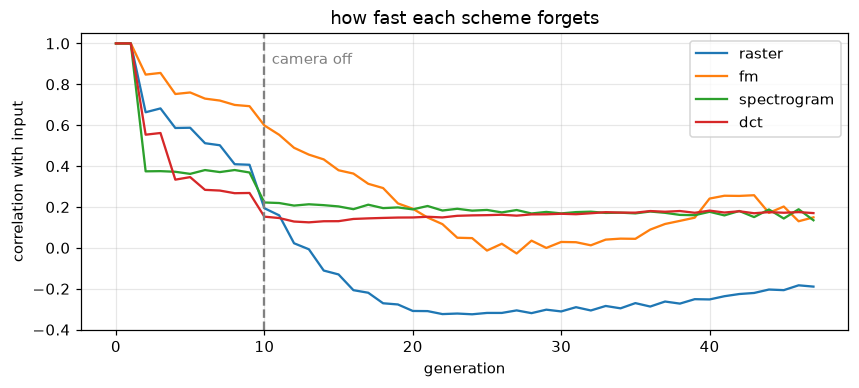

In [ ]:
# Plot correlation of each generation's image to the original input
plt.figure(figsize=(9, 3.5))

# One line per codec: how similar each generation's image is to the original
# (1 = same structure, 0 = unrelated, negative = brightness inverted)
for name, (frames, _) in runs.items():
    plt.plot([corr(f, img) for f in frames], label=name)

# Mark the generation where the camera input stops
plt.axvline(CAMERA_GENS, ls="--", c="gray"); plt.text(CAMERA_GENS + 0.5, 0.9, "camera off", color="gray")

# Axes: generation number vs. similarity to the input
plt.xlabel("generation"); plt.ylabel("correlation with input"); plt.ylim(-0.4, 1.05)
plt.legend(); plt.grid(alpha=0.3); plt.title("how fast each scheme forgets"); plt.show()

### Listen to the decay

Each clip is the whole run: 10 generations with the camera on, then the loop running alone.

In [62]:
for name, (_, audio) in runs.items():
    print(name); display(Audio(audio, rate=cfg.fs))

raster


fm


spectrogram


dct


## 7. Tuning the loop: feedback and blending

With the camera always on, `feedback` decides how much the image *ghosts* (trails behind) versus how closely it tracks the camera.
Higher feedback gives longer memory and more of the room's character.

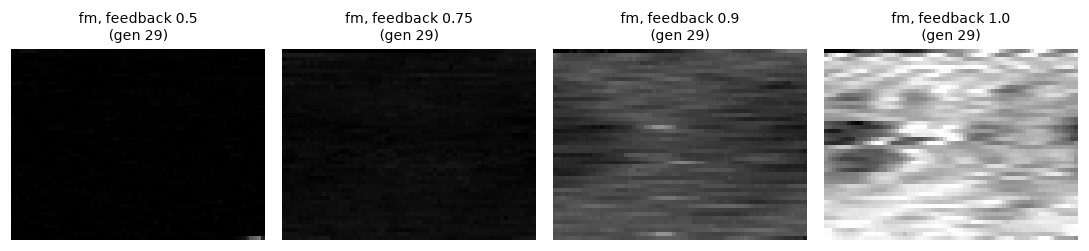

In [63]:
fig, axes = plt.subplots(1, 4, figsize=(10, 2.4))
for ax, fb in zip(axes, [0.5, 0.75, 0.9, 1.0]):
    frames, _ = run_generations(LoopConfig(codec="fm", feedback=fb), img, 30, camera_gens=10)
    ax.imshow(frames[-1], vmin=0, vmax=1); ax.axis("off"); ax.set_title(f"fm, feedback {fb}\n(gen 29)", fontsize=9)
plt.tight_layout(); plt.show()

## 8. todo

- Test with live video feed
- Swap in physically modeled room: `channel.shoebox_ir(...)` (pyroomacoustics), or real room's measured impulse response
- Test with real speaker and mic and compare the curves in section 6